# B-8802B — temperatura em nível ou em diferença, para o detector de mudança de conceito

**O que está em teste:** o **monitor de mudança de conceito** (teste KS diário, M6). O modelo de anomalia não entra aqui.

**Pergunta:** a temperatura do mancal muda cerca de 6 °C com a estação, o mesmo tamanho das mudanças reais que queremos pegar.
Comparar a **diferença entre temperaturas** (mancal da bomba − mancal do motor, LA − LNA) tira a estação, porque os
dois sentem o mesmo ambiente. Isso ajuda?

**Montagem:**
- dado de jan/2025 a ago/2026, com os mesmos filtros do bundle B-8802B-2025 (bomba operando, transientes, dado congelado);
- KS calibrado igual ao M6 de produção: limiar = maior D da própria referência, dispara com 3 de 5 dias acima;
- duas referências:
  - **2025 inteiro**, como está em produção;
  - **jan–mar/2025**, uma referência curta, como a de um modelo de 1 a 3 meses. Ela não cobre o inverno, então é o teste de sazonalidade.

In [1]:
from pathlib import Path
import sys
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

SAVE_PLOTS = False
ROOT = Path.cwd()
while not (ROOT / "deploy_v2").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
D = ROOT / "deploy_v2" / "Transpetro"
sys.path.insert(0, str(D))
import simpred_inference as si, monitor_drift as md

EQUIP = "B-8802B"
B = next((D / "B-8802B-2025" / "modelos").iterdir())
raw = si.carregar_dados(si.achar_csv(D / "B-8802B-2025" / "dados", "data_2025-01-01_2026-08-10_raw.csv"))
df = md._sem_congelado(B, md._temporal_steps(B, raw, todos_sensores=True))
df["Δ bomba LA − motor LA"] = df["Temperatura Bomba LA"] - df["Temperatura Motor LA"]
df["Δ bomba LNA − motor LNA"] = df["Temperatura Bomba LNA"] - df["Temperatura Motor LNA"]
df["Δ bomba LA − bomba LNA"] = df["Temperatura Bomba LA"] - df["Temperatura Bomba LNA"]
NIVEL = ["Temperatura Bomba LA", "Temperatura Bomba LNA", "Temperatura Motor LA", "Temperatura Motor LNA"]
DIF = [c for c in df.columns if c.startswith("Δ")]
print(f"{len(df):,} instantes de 5 min com a bomba operando, {df.index.min():%d/%m/%Y} a {df.index.max():%d/%m/%Y}")

134,520 instantes de 5 min com a bomba operando, 01/01/2025 a 10/08/2026


## KS em nível × KS em diferença

In [2]:
def episodios(fires, gap_dias=10):
    """Agrupa disparos seguidos (o detector reseta e volta a disparar enquanto a mudança continua)."""
    eps = []
    for t, f in fires:
        if eps and (t - eps[-1]["fim"]).days <= gap_dias:
            eps[-1]["fim"] = t; eps[-1]["sensores"] |= set(f); eps[-1]["n"] += 1
        else:
            eps.append({"início": t, "fim": t, "sensores": set(f), "n": 1})
    return eps

linhas, d_crit = [], {}
for ri, rf, nref in (("2025-01-01", "2025-12-31", "2025 inteiro"), ("2025-01-01", "2025-03-31", "jan–mar/2025")):
    for cols, nome in ((NIVEL, "nível"), (DIF, "diferença")):
        det = md.CalibratedKSDetector(df.loc[ri:rf, cols], window_size=288, k_consecutive=3, persistence_window=5,
                                      n_reference=2000, sampling="quantile")
        _, fires = det.scan(df[cols], reset_gap="3D")
        d_crit[(nref, nome)] = dict(zip(cols, np.round(det.d_crit, 2)))
        for e in episodios(fires):
            linhas.append({"referência": nref, "KS em": nome, "1º disparo": e["início"].date(), "último": e["fim"].date(),
                           "disparos": e["n"], "sensores": ", ".join(sorted(e["sensores"]))})
        if not fires:
            linhas.append({"referência": nref, "KS em": nome, "1º disparo": "nenhum"})
tab = pd.DataFrame(linhas)
pd.set_option("display.max_colwidth", 120)
tab

,referência,KS em,1º disparo,último,disparos,sensores
0,2025 inteiro,nível,2026-06-21,2026-06-21,1,Temperatura Bomba LA
1,2025 inteiro,diferença,2026-04-02,2026-05-06,9,Δ bomba LA − motor LA
2,jan–mar/2025,nível,2025-04-09,2025-05-11,8,Temperatura Bomba LNA
3,jan–mar/2025,nível,2025-05-26,2025-11-26,43,"Temperatura Bomba LA, Temperatura Bomba LNA, Temperatura Motor LA, Temperatura Motor LNA"
4,jan–mar/2025,nível,2025-12-09,2026-01-05,5,"Temperatura Bomba LNA, Temperatura Motor LA"
5,jan–mar/2025,nível,2026-01-21,2026-01-25,2,Temperatura Bomba LNA
6,jan–mar/2025,nível,2026-02-11,2026-02-22,3,"Temperatura Bomba LNA, Temperatura Motor LNA"
7,jan–mar/2025,nível,2026-03-11,2026-08-03,38,"Temperatura Bomba LA, Temperatura Bomba LNA, Temperatura Motor LA"
8,jan–mar/2025,diferença,2025-04-10,2025-05-11,8,Δ bomba LA − bomba LNA
9,jan–mar/2025,diferença,2025-05-26,2026-02-22,66,"Δ bomba LA − bomba LNA, Δ bomba LA − motor LA, Δ bomba LNA − motor LNA"


In [3]:
pd.DataFrame(d_crit).T  # limiar de D de cada sensor (perto de 1 = o detector fica cego para esse sensor)

Temperatura Bomba LA  Temperatura Bomba LNA  \
2025 inteiro nível                      0.97                   0.99   
             diferença                   NaN                    NaN   
jan–mar/2025 nível                      0.95                   0.90   
             diferença                   NaN                    NaN   

                        Temperatura Motor LA  Temperatura Motor LNA  \
2025 inteiro nível                      0.93                   0.94   
             diferença                   NaN                    NaN   
jan–mar/2025 nível                      0.67                   0.76   
             diferença                   NaN                    NaN   

                        Δ bomba LA − motor LA  Δ bomba LNA − motor LNA  \
2025 inteiro nível                        NaN                      NaN   
             diferença                   0.95                     0.99   
jan–mar/2025 nível                        NaN                      NaN   
             diferença                   0.83                     0.92   

                        Δ bomba LA − bomba LNA  
2025 inteiro nível                         NaN  
             diferença                    0.98  
jan–mar/2025 nível                         NaN  
             diferença                    0.84

## A série diária

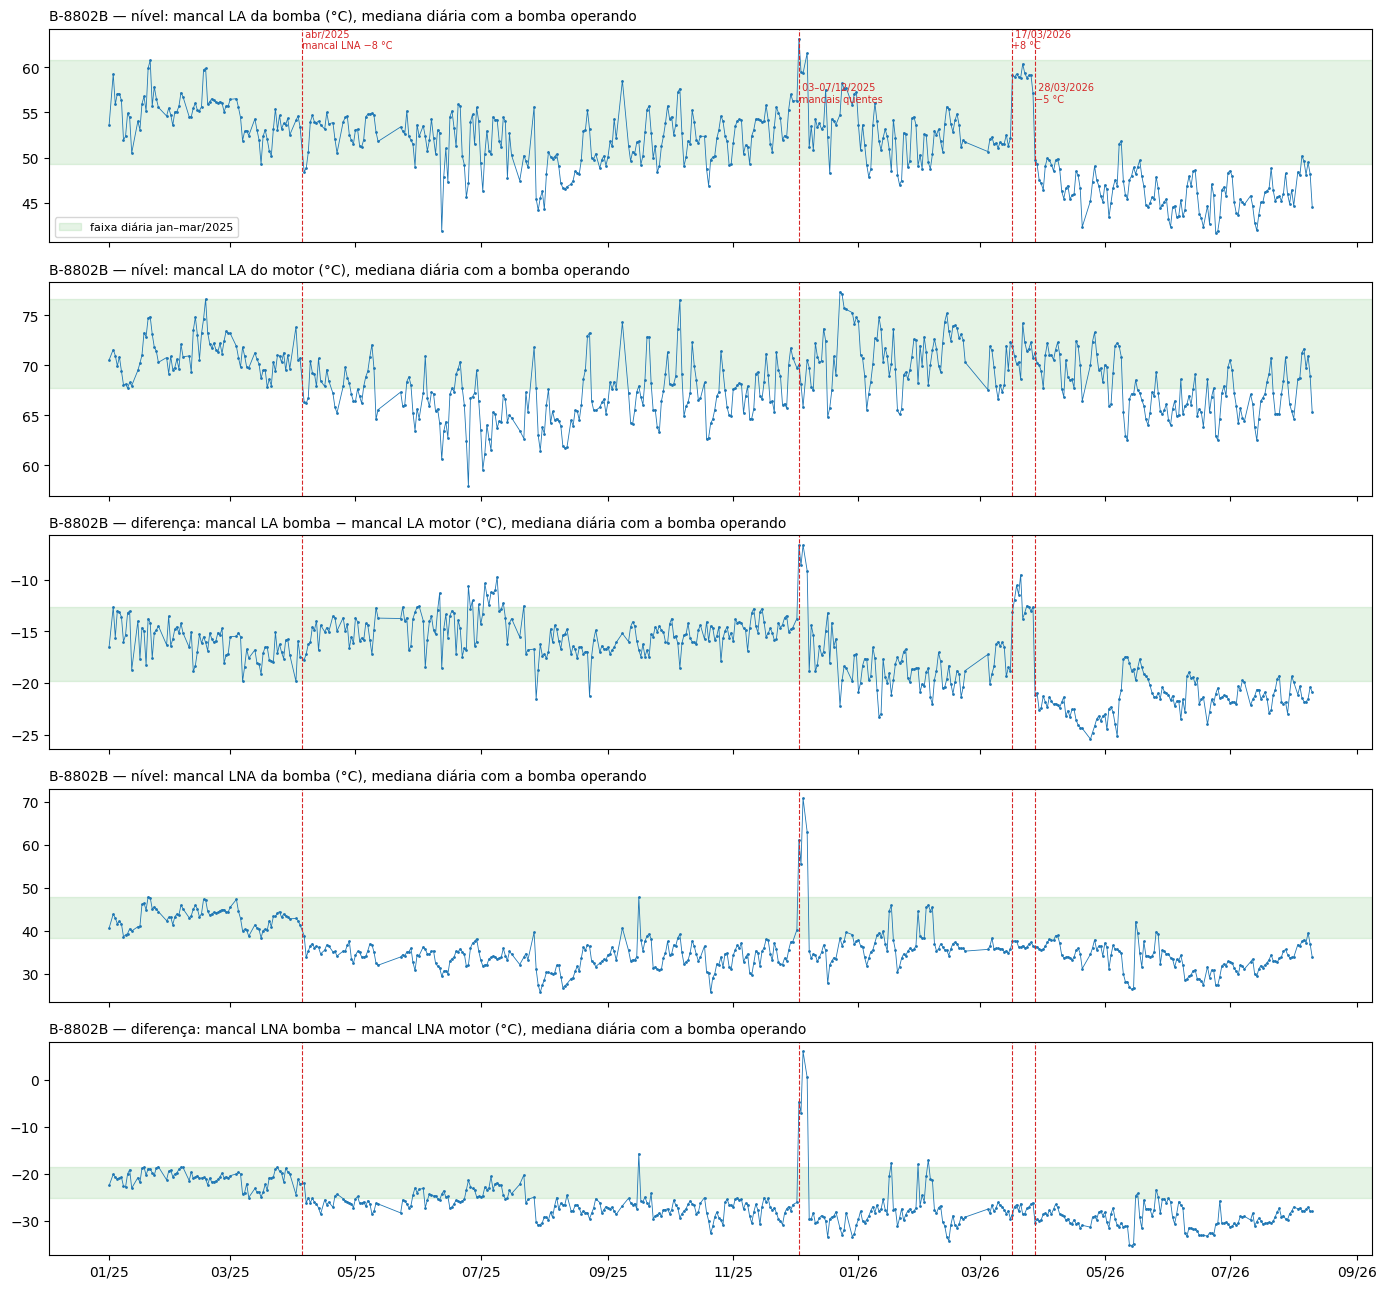

In [4]:
g = df.resample("D")
dia = pd.DataFrame({c: g[c].median() for c in NIVEL + DIF})
dia = dia[g["Temperatura Bomba LA"].count() >= 72]          # dias com pelo menos 6 h de operação
REF = dia.loc["2025-01-01":"2025-03-31"]
EVENTOS = {"abr/2025\nmancal LNA −8 °C": "2025-04-05", "03–07/12/2025\nmancais quentes": "2025-12-03",
           "17/03/2026\n+8 °C": "2026-03-17", "28/03/2026\n−5 °C": "2026-03-28"}

paineis = [("Temperatura Bomba LA", "nível: mancal LA da bomba (°C)"),
           ("Temperatura Motor LA", "nível: mancal LA do motor (°C)"),
           ("Δ bomba LA − motor LA", "diferença: mancal LA bomba − mancal LA motor (°C)"),
           ("Temperatura Bomba LNA", "nível: mancal LNA da bomba (°C)"),
           ("Δ bomba LNA − motor LNA", "diferença: mancal LNA bomba − mancal LNA motor (°C)")]
fig, axs = plt.subplots(len(paineis), 1, figsize=(14, 13), sharex=True)
for ax, (c, tit) in zip(axs, paineis):
    ax.plot(dia.index, dia[c], ".-", ms=2, lw=0.6, color="tab:blue")
    lo, hi = REF[c].min(), REF[c].max()
    ax.axhspan(lo, hi, color="tab:green", alpha=0.12, label="faixa diária jan–mar/2025")
    for nome, t in EVENTOS.items():
        ax.axvline(pd.Timestamp(t), color="tab:red", lw=0.8, ls="--")
    ax.set_title(f"{EQUIP} — {tit}, mediana diária com a bomba operando", fontsize=10, loc="left")
for i, (nome, t) in enumerate(EVENTOS.items()):
    y0, y1 = axs[0].get_ylim()
    axs[0].text(pd.Timestamp(t), y1 - (0.0 if i % 2 == 0 else 0.25) * (y1 - y0), " " + nome, color="tab:red", fontsize=7, va="top")
axs[0].legend(loc="lower left", fontsize=8)
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
fig.tight_layout(); plt.show()

## O que dá para concluir

Aqui o assunto é só o **monitor de mudança de conceito**, não o modelo de anomalia.

**1. A diferença reduz a estação, mas não zera.**
- Com a referência curta (jan–mar/2025), o KS em nível dispara o ano todo, puxado pelas temperaturas do **motor**, que só seguem o ambiente.
- A diferença **bomba LA − motor LA** não dispara no inverno de 2025: o primeiro disparo dela é em 15/01/2026.
- No gráfico, porém, ela ainda sobe cerca de 3 °C em jun–jul/2025. A estação diminui, mas não some.

**2. Com a referência de produção (2025 inteiro):**
- o KS em nível só percebe a mudança de março/2026 em **21/06/2026**;
- a diferença percebe em **02/04/2026**, 5 dias depois, igual ao M8.

**3. Apareceram duas mudanças antigas que nenhum detector avisou:**
- **Início de abril/2025:**
  - o mancal LNA da bomba caiu cerca de 8 °C (43 para 35 °C) e o motor não acompanhou;
  - a diferença LA − LNA da bomba dispara a partir de 10/04/2025.
- **03 a 07/12/2025:**
  - o mancal LNA da bomba foi de cerca de 35 °C para **61 a 71 °C** e o LA de 56 para 59–63 °C, com o motor normal;
  - em 08/12 voltou ao normal, mas a diferença bomba LA − motor LA ficou cerca de 4 °C mais baixa até março (−14,6 → −18,7);
  - é anomalia real nos sensores de temperatura dos mancais da bomba e pode indicar problema de lubrificação ou intervenção no mancal: **vale perguntar à operação**;
  - o modelo de anomalia teve um alarme curto em 06/12/2025 (ele não usa o mancal LNA).

**4. Por que o período quente de 18 a 26/03/2026 passou:** a referência de 2025 contém o episódio de dezembro e a mudança de abril. Por isso o limiar do KS fica perto de 1 (0,95 a 0,99) e o detector aprende que "quente assim é normal". Referência suja deixa o detector cego.

**Próximos passos sugeridos:**
- monitorar as diferenças de temperatura (incluindo o mancal LNA, que hoje está fora) no lugar do nível;
- limpar a referência, tirando o episódio de dezembro/2025 e tratando a mudança de abril/2025, depois de confirmar com a operação;
- trocar o KS por um controle do nível da diferença (mediana diária fora da faixa), que é mais simples de explicar e não satura com amostra grande;
- se a estação ainda atrapalhar, usar o resíduo de regressão (como o M8) em vez da diferença pura.